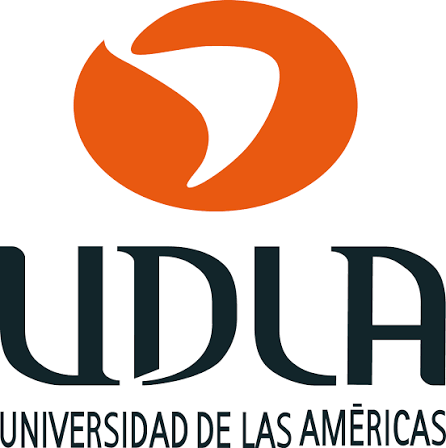

**Universidad de las Américas · Diplomado en Ingeniería de Datos con Python**<br>
DPL1056 · Herramientas y Entornos para Ciencia de Datos

---

# Taller S2 · Selección de gráficos por tarea analítica: panel global y datos geoespaciales

**Sesión 2 · martes 17-11-2026** · Unidad 1 · RAA1

| Dimensión | Resultado de aprendizaje de la sesión |
|---|---|
| Conceptual | Justificar la elección de una visualización a partir del tipo de dato, la tarea analítica y la escala. |
| Procedimental | Construir visualizaciones estadísticas declarativas (seaborn.objects), interactivas (plotly) y geoespaciales a partir de dos APIs públicas. |
| Actitudinal | Evaluar críticamente los sesgos de cobertura de las fuentes de datos antes de comunicar hallazgos. |

**Fuentes de la sesión**

| Fuente | Tipo de dato | Acceso | Licencia |
|---|---|---|---|
| Banco Mundial · WDI | Panel país × año (cuantitativo, temporal, categórico) | API REST v2 | CC BY 4.0 |
| OpenStreetMap · Overpass API | Puntos con etiquetas (espacial, categórico) | Overpass QL | ODbL · © colaboradores de OpenStreetMap |

**Antes de empezar:** *Archivo → Guardar una copia en Drive*. Trabaje sobre su copia.

### Eje del curso: contar historias con datos

El curso sigue las seis lecciones de Knaflic (2015): entender el contexto, elegir el gráfico adecuado, eliminar el desorden, dirigir la atención, pensar como diseñador y contar una historia. Hoy se trabajan las dos primeras.

**Antes de graficar, escriba la Big Idea:** una oración con punto de vista que responda tres preguntas: ¿quién decide?, ¿qué debe hacer? y ¿qué está en juego?

> Plantilla: *Para [audiencia], [hallazgo] implica [acción], porque [qué está en juego].*

La Big Idea se escribe antes de abrir los datos y se corrige al final si los datos la contradicen.

## 1. Entorno y utilidades

In [ ]:
import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn.objects as so
import plotly
import plotly.express as px
from scipy.spatial import cKDTree

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| seaborn", sns.__version__,
      "| plotly", plotly.__version__)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
NARANJO, PETROLEO, GRIS = "#E95911", "#12252A", "#9AA0A6"
DATOS = Path("datos")
DATOS.mkdir(exist_ok=True)

# Contingencia: si el docente lo indica, cambie a True para cargar los respaldos de Blackboard sin consultar las APIs
USAR_RESPALDO = False

In [ ]:
def crear_sesion(user_agent="DPL1056-UDLA-curso/1.0 (uso academico)"):
    """Sesión HTTP con reintentos y un User-Agent que identifica al curso."""
    reintentos = Retry(total=3, connect=3, read=3, backoff_factor=2,
                       status_forcelist=[429, 500, 502, 503, 504],
                       allowed_methods=["GET", "POST"], respect_retry_after_header=True)
    sesion = requests.Session()
    sesion.headers["User-Agent"] = user_agent
    sesion.mount("https://", HTTPAdapter(max_retries=reintentos))
    return sesion


SESION = crear_sesion()


def con_cache(ruta, funcion, *args, **kwargs):
    """Ejecuta funcion(*args) solo si ruta no existe; si existe, lee el CSV guardado."""
    ruta = Path(ruta)
    if ruta.exists():
        return pd.read_csv(ruta)
    df = funcion(*args, **kwargs)
    df.to_csv(ruta, index=False)
    return df


def leer_respaldo(ruta):
    """Lee un CSV de respaldo; en Colab muestra un botón para subirlo si no está."""
    ruta = Path(ruta)
    if not ruta.exists():
        try:
            from google.colab import files
            print(f"Suba {ruta.name} (Blackboard → Semana 2):")
            subidos = files.upload()
            csv = next((nombre for nombre in subidos if nombre.endswith(".csv")), None)
            if csv and Path(csv) != ruta:
                Path(csv).rename(ruta)
        except ImportError:
            pass
    if not ruta.exists():
        raise FileNotFoundError(
            f"No se encontró {ruta.name}. Descárguelo desde Blackboard → Semana 2 "
            "y súbalo al panel Archivos de Colab (ícono de carpeta → ícono de subir)."
        )
    return pd.read_csv(ruta)

## 2. Panel global del Banco Mundial

En S1 se trabajó con 9 países. Para estudiar **distribuciones** y **relaciones** se necesita una población: todas las economías del Banco Mundial, con su región y su grupo de ingreso.

Dos endpoints:

- `/v2/country` → metadatos de cada economía (región, grupo de ingreso). Los agregados (regiones, grupos) traen la región `Aggregates` y se descartan.
- `/v2/country/all/indicator/{código}` → el indicador para todas las economías, paginado.

In [ ]:
WB = "https://api.worldbank.org/v2"
INDICADORES = {
    "SP.DYN.LE00.IN": "esperanza_vida",
    "NY.GDP.PCAP.PP.KD": "pib_pc_ppa",
    "SP.POP.TOTL": "poblacion",
}
DESDE, HASTA = 2000, 2024
REGIONES = {
    "EAS": "Asia oriental y Pacífico", "ECS": "Europa y Asia central",
    "LCN": "América Latina y el Caribe", "MEA": "Oriente Medio y Norte de África",
    "NAC": "América del Norte", "SAS": "Asia meridional", "SSF": "África subsahariana",
}
INGRESOS = {"HIC": "Alto", "UMC": "Medio alto", "LMC": "Medio bajo", "LIC": "Bajo"}
ORDEN_INGRESO = ["Bajo", "Medio bajo", "Medio alto", "Alto"]


def wb_paginas(url, params, prefijo, timeout=(10, 90)):
    """Recorre todas las páginas de un endpoint del Banco Mundial.

    Cada página se guarda en datos/{prefijo}_p{n}.json: si una página falla,
    al volver a ejecutar se retoma desde esa página sin repetir las anteriores.
    """
    params = {**params, "format": "json", "page": 1}
    registros = []
    while True:
        archivo = DATOS / f"{prefijo}_p{params['page']}.json"
        if archivo.exists():
            cuerpo = json.loads(archivo.read_text())
        else:
            r = SESION.get(url, params=params, timeout=timeout)
            r.raise_for_status()
            cuerpo = r.json()
            if len(cuerpo) < 2 or cuerpo[1] is None:
                raise ValueError(f"Respuesta sin datos: {cuerpo[0]}")
            archivo.write_text(json.dumps(cuerpo))
            print(f"p{params['page']}/{cuerpo[0]['pages']}", end=" ")
        registros.extend(cuerpo[1])
        if params["page"] >= int(cuerpo[0]["pages"]):
            return registros
        params["page"] += 1
        time.sleep(0.2)


def wb_metadatos():
    regs = wb_paginas(f"{WB}/country", {"per_page": 400}, prefijo="wb_meta")
    return pd.DataFrame({
        "iso3": [r["id"] for r in regs],
        "nombre": [r["name"] for r in regs],
        "region_id": [r["region"]["id"] for r in regs],
        "region_en": [r["region"]["value"] for r in regs],
        "ingreso_id": [r["incomeLevel"]["id"] for r in regs],
    })


def wb_indicador(codigo):
    regs = wb_paginas(f"{WB}/country/all/indicator/{codigo}", {"date": f"{DESDE}:{HASTA}", "per_page": 500},
                      prefijo=f"wb_{codigo}")
    return pd.DataFrame({
        "iso3": [r["countryiso3code"] for r in regs],
        "anio": [int(r["date"]) for r in regs],
        "variable": INDICADORES[codigo],
        "valor": [r["value"] for r in regs],
    })

In [ ]:
RESPALDO_WDI = Path("wdi_global_respaldo.csv")


def cargar_panel():
    meta = con_cache(DATOS / "wb_metadatos.csv", wb_metadatos)
    largos = []
    for codigo in INDICADORES:
        print("Indicador", codigo, end=" … ")
        largos.append(con_cache(DATOS / f"wb_{codigo}.csv", wb_indicador, codigo))
        print("ok")
    largo = pd.concat(largos, ignore_index=True)
    ancho = (largo.pivot_table(index=["iso3", "anio"], columns="variable", values="valor")
                  .reset_index())
    ancho.columns.name = None
    meta = meta[meta["region_en"] != "Aggregates"].copy()
    meta["region"] = meta["region_id"].map(REGIONES).fillna(meta["region_en"])
    meta["ingreso"] = meta["ingreso_id"].map(INGRESOS)
    panel = ancho.merge(meta[["iso3", "nombre", "region", "ingreso"]], on="iso3", how="inner")
    panel["ingreso"] = pd.Categorical(panel["ingreso"], categories=ORDEN_INGRESO, ordered=True)
    return panel


try:
    if USAR_RESPALDO:
        raise ValueError("USAR_RESPALDO = True")
    panel = cargar_panel()
    print("Fuente: API Banco Mundial")
except (requests.RequestException, ValueError) as error:
    print("\nAPI no usada →", type(error).__name__, "· se usa el respaldo de Blackboard")
    print("Si la API alcanzó a descargar páginas, vuelva a ejecutar esta celda: retoma donde quedó.")
    panel = leer_respaldo(RESPALDO_WDI)
    panel["ingreso"] = pd.Categorical(panel["ingreso"], categories=ORDEN_INGRESO, ordered=True)

print(panel.shape, "·", panel["iso3"].nunique(), "economías")
panel.sample(5, random_state=1)

**Perfil de datos antes de graficar.** ¿Cuántas economías tienen dato por año? Un gráfico de 2024 que omite en silencio a un tercio de los países comunica algo distinto a lo que aparenta.

In [ ]:
cobertura = (panel.groupby("anio")[list(INDICADORES.values())].count()
                  .rename(columns=lambda c: f"n_{c}"))
cobertura.tail(6)

In [ ]:
# Año de análisis: el más reciente con ≥ 90 % de cobertura en esperanza de vida y PIB per cápita
n_total = panel["iso3"].nunique()
completos = panel.dropna(subset=["esperanza_vida", "pib_pc_ppa"]).groupby("anio")["iso3"].nunique()
ANIO = int(completos[completos >= 0.9 * completos.max()].index.max())
corte = panel[panel["anio"] == ANIO].dropna(subset=["esperanza_vida", "pib_pc_ppa"])
print(f"Año de análisis: {ANIO} · {len(corte)} de {n_total} economías con ambos indicadores")

## 3. Gramática de gráficos con `seaborn.objects`

La gramática de gráficos (Wilkinson, 2005) separa un gráfico en componentes independientes:

| Componente | Pregunta que responde | En `seaborn.objects` |
|---|---|---|
| Datos | ¿Qué tabla, en qué formato? | `so.Plot(df, ...)` (formato largo) |
| Mapeo estético | ¿Qué variable va a qué canal? | `x=`, `y=`, `color=`, `pointsize=` |
| Marca | ¿Con qué forma se dibuja? | `so.Dots()`, `so.Line()`, `so.Bars()`, `so.Area()` |
| Transformación estadística | ¿Se dibuja el dato o un resumen? | `so.Hist()`, `so.KDE()`, `so.Agg()`, `so.Est()`, `so.PolyFit()` |
| Escala | ¿Cómo se traduce el valor al canal? | `.scale(x="log")` |
| Facetas | ¿Se divide en paneles? | `.facet(col=..., wrap=...)` |

Cambiar un componente no obliga a reescribir el gráfico: esa es la ventaja frente a la API imperativa de matplotlib vista en S1.

### 3.1 Distribuciones: el estimador también es una decisión

**Pregunta:** ¿cómo se distribuye la esperanza de vida entre economías según su grupo de ingreso?

Histograma y KDE dependen de un parámetro (ancho de clase, ancho de banda) que puede crear o borrar modas. Compare las tres versiones.

In [ ]:
base = (so.Plot(corte.dropna(subset=["ingreso"]), x="esperanza_vida", color="ingreso")
        .scale(color=so.Nominal("viridis", order=ORDEN_INGRESO)))

fig = plt.figure(figsize=(13, 3.6))
subfigs = fig.subfigures(1, 3)
(base.add(so.Bars(), so.Hist(bins=6)).label(title="Histograma · 6 clases", x="Años")
     .on(subfigs[0]).plot())
(base.add(so.Bars(), so.Hist(bins=40)).label(title="Histograma · 40 clases", x="Años")
     .on(subfigs[1]).plot())
(base.add(so.Line(linewidth=2), so.KDE(bw_adjust=0.4)).label(title="KDE · bw_adjust = 0,4", x="Años")
     .on(subfigs[2]).plot())
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.ecdfplot(data=corte.dropna(subset=["ingreso"]), x="esperanza_vida", hue="ingreso",
             hue_order=ORDEN_INGRESO, palette="viridis", linewidth=2, ax=ax)
ax.axhline(0.5, color=GRIS, linestyle=":", linewidth=1)
ax.set(title=f"Distribución acumulada de la esperanza de vida por grupo de ingreso ({ANIO})",
       xlabel="Esperanza de vida al nacer (años)", ylabel="Proporción de economías")
plt.show()

**Lectura de la ECDF:** el cruce de cada curva con la línea punteada (0,5) es la mediana del grupo. La ECDF no tiene parámetros de suavizado: muestra todos los datos. Su costo es una lectura menos intuitiva para audiencias no técnicas.

**Discusión:** ¿qué estimador usaría para un informe ejecutivo y cuál para un análisis exploratorio? Justifique con la tarea.

### 3.2 Relaciones: la escala es parte del argumento

**Pregunta:** ¿cómo se relacionan el ingreso por habitante y la esperanza de vida?

El PIB per cápita abarca dos órdenes de magnitud. En escala lineal, la mayoría de los países queda comprimida a la izquierda. En escala logarítmica, una misma distancia horizontal representa una misma **razón** de ingreso: duplicar de 1.000 a 2.000 USD equivale a duplicar de 20.000 a 40.000 USD.

In [ ]:
graf = (
    so.Plot(corte, x="pib_pc_ppa", y="esperanza_vida")
    .add(so.Dots(alpha=0.75, pointsize=4), color="region")
    .add(so.Line(color=PETROLEO, linewidth=2), so.PolyFit(order=1))
    .label(x="PIB per cápita, USD PPA constantes", y="Esperanza de vida (años)", color="Región")
)
fig = plt.figure(figsize=(12, 4.2))
subfigs = fig.subfigures(1, 2)
graf.label(title="Escala lineal").on(subfigs[0]).plot()
graf.scale(x="log").label(title="Escala logarítmica").on(subfigs[1]).plot()
plt.show()

La recta de ajuste se calcula **después** de transformar la escala: en el panel logarítmico, `so.PolyFit` ajusta esperanza de vida contra log(PIB). Pregunta: ¿qué panel muestra una relación mejor descrita por una recta, y qué implica eso sobre rendimientos decrecientes del ingreso?

### 3.3 Facetas y resumen estadístico: evolución por región

**Pregunta:** ¿se cerró la brecha de esperanza de vida entre regiones desde 2000?

`so.Est` resume cada año con la **mediana** y una banda del rango intercuartílico (percentiles 25–75). La banda comunica dispersión; una línea sola la oculta.

In [ ]:
(
    so.Plot(panel.dropna(subset=["esperanza_vida"]), x="anio", y="esperanza_vida")
    .facet(col="region", wrap=4)
    .add(so.Band(color=NARANJO, alpha=0.25), so.Est("median", errorbar=("pi", 50)))
    .add(so.Line(color=NARANJO, linewidth=2), so.Agg("median"))
    .label(x="", y="Años", title="{}".format)
    .layout(size=(13, 5.5))
)

### 3.4 Interactividad con propósito: plotly

La interactividad agrega valor cuando el usuario necesita **identificar** casos (hover) o **recorrer** una dimensión (tiempo). Animación de 2000 a 2024: tamaño = población, color = región, eje X logarítmico.

Los rangos de los ejes se fijan para que no cambien entre cuadros: un eje que se reescala en cada año destruye la comparación.

In [ ]:
anim = panel.dropna(subset=["esperanza_vida", "pib_pc_ppa", "poblacion", "region"]).sort_values("anio")
fig = px.scatter(
    anim, x="pib_pc_ppa", y="esperanza_vida", size="poblacion", color="region",
    animation_frame="anio", animation_group="iso3", hover_name="nombre",
    log_x=True, size_max=55,
    range_x=[anim["pib_pc_ppa"].min() * 0.8, anim["pib_pc_ppa"].max() * 1.2],
    range_y=[anim["esperanza_vida"].min() - 2, anim["esperanza_vida"].max() + 2],
    labels={"pib_pc_ppa": "PIB per cápita (USD PPA, escala log)", "esperanza_vida": "Esperanza de vida (años)",
            "region": "Región", "anio": "Año"},
    title="Ingreso y esperanza de vida, 2000–2024 · Fuente: Banco Mundial (WDI)",
    height=560,
)
fig.show()

## 4. Datos geoespaciales: OpenStreetMap vía Overpass

OpenStreetMap (OSM) es una base de datos geográfica colaborativa. Su modelo tiene tres tipos de elementos, todos con **etiquetas** `clave=valor`:

| Elemento | Qué representa | Ejemplo |
|---|---|---|
| `node` | Un punto (lat, lon) | Una farmacia mapeada como punto |
| `way` | Una secuencia de nodos (línea o polígono) | El contorno de un edificio |
| `relation` | Un grupo de elementos | El límite de una comuna |

**Overpass QL** es el lenguaje para consultarla. Flujo de trabajo recomendado:

1. Prototipar la consulta en <https://overpass-turbo.eu> (mapa, inspección de etiquetas, asistente).
2. Reemplazar los atajos propios de overpass-turbo (`{{geocodeArea:…}}`, `{{bbox}}`) por filtros de Overpass QL estándar.
3. Ejecutar desde Python con caché, User-Agent y servidor alternativo.

**Consulta en overpass-turbo** (pegue y presione *Ejecutar*):

```
[out:json][timeout:60];
{{geocodeArea:Providencia, Santiago}}->.zona;
nwr["amenity"="pharmacy"](area.zona);
out center;
```

**Misma consulta para la API**, sin atajos. El área se define por la etiqueta `ISO3166-2` de la región:

```
[out:json][timeout:90];
area["ISO3166-2"="CL-RM"]->.rm;
nwr["amenity"="pharmacy"](area.rm);
out center;
```

`nwr` = nodes, ways y relations. `out center` entrega coordenadas para los tres tipos: los nodos traen `lat`/`lon` y los ways y relations traen un `center`.

**Uso responsable:** el servidor principal es un servicio comunitario sin garantías de disponibilidad y limita el consumo por IP. Use caché, una consulta a la vez y cite la fuente: «© colaboradores de OpenStreetMap, ODbL».

In [ ]:
OVERPASS = [
    "https://overpass-api.de/api/interpreter",
    "https://overpass.private.coffee/api/interpreter",
]
PLANTILLA_QL = """[out:json][timeout:90];
(area["ISO3166-2"="CL-RM"]; area["name"="Región Metropolitana de Santiago"]["admin_level"="4"];)->.rm;
nwr["{clave}"="{valor}"](area.rm);
out center;"""


def overpass(consulta, timeout=(10, 120)):
    """Envía una consulta Overpass QL; si un servidor falla, prueba el siguiente."""
    ultimo_error = None
    for url in OVERPASS:
        try:
            r = SESION.post(url, data={"data": consulta}, timeout=timeout)
            r.raise_for_status()
            cuerpo = r.json()
            if not cuerpo.get("elements") and "remark" in cuerpo:
                raise ValueError(f"Overpass: {cuerpo['remark']}")
            return cuerpo["elements"]
        except (requests.RequestException, ValueError) as error:
            print(f"  {url.split('/')[2]} no respondió ({type(error).__name__}); probando el siguiente…")
            ultimo_error = error
    raise ultimo_error


def elementos_a_tabla(elementos, categoria):
    """Aplana la respuesta de Overpass: una fila por elemento con coordenadas y etiquetas útiles."""
    filas = []
    for e in elementos:
        punto = e if e["type"] == "node" else e.get("center")
        if not punto:
            continue
        etiquetas = e.get("tags", {})
        filas.append({
            "categoria": categoria, "osm_tipo": e["type"], "osm_id": e["id"],
            "lat": punto["lat"], "lon": punto["lon"],
            "nombre": etiquetas.get("name"), "marca": etiquetas.get("brand"),
            "operador": etiquetas.get("operator"), "comuna_dir": etiquetas.get("addr:city"),
        })
    return pd.DataFrame(filas)


def descargar_osm(clave, valor):
    consulta = PLANTILLA_QL.format(clave=clave, valor=valor)
    return elementos_a_tabla(overpass(consulta), f"{clave}={valor}")


RESPALDO_OSM = Path("osm_rm_respaldo.csv")


def cargar_osm(clave, valor):
    try:
        if USAR_RESPALDO:
            raise ValueError("USAR_RESPALDO = True")
        return con_cache(DATOS / f"osm_{clave}_{valor}.csv", descargar_osm, clave, valor)
    except (requests.RequestException, ValueError) as error:
        print("Overpass no usado →", type(error).__name__, "· se usa el respaldo de Blackboard")
        respaldo = leer_respaldo(RESPALDO_OSM)
        return respaldo[respaldo["categoria"] == f"{clave}={valor}"].reset_index(drop=True)


farmacias = cargar_osm("amenity", "pharmacy")
print(farmacias.shape)
farmacias.head()

### 4.1 Perfil de calidad: ¿qué tan completos son los datos voluntarios?

OSM refleja lo que la comunidad mapeó, no un registro oficial. Antes de concluir sobre "dónde hay farmacias", mida la completitud de las etiquetas.

In [ ]:
perfil = pd.Series({
    "elementos": len(farmacias),
    "% nodos": (farmacias["osm_tipo"] == "node").mean() * 100,
    "% con nombre": farmacias["nombre"].notna().mean() * 100,
    "% con marca (brand)": farmacias["marca"].notna().mean() * 100,
    "% con comuna en dirección": farmacias["comuna_dir"].notna().mean() * 100,
}).round(1)
perfil

### 4.2 Limpieza: normalizar cadenas

La etiqueta `brand` no siempre está; el nombre suele contener la cadena con variantes ("Farmacia Cruz Verde", "CRUZ VERDE"). Se normaliza con patrones sobre `marca` y `nombre`.

In [ ]:
CADENAS = {
    "Cruz Verde": r"cruz\s*verde",
    "Salcobrand": r"salco",
    "Ahumada": r"ahumada",
    "Dr. Simi": r"simi",
    "Knop": r"knop",
}


def normalizar_cadena(df, patrones, otra="Independiente u otra"):
    texto = (df["marca"].fillna("") + " " + df["nombre"].fillna("")).str.lower()
    resultado = pd.Series(otra, index=df.index)
    for cadena, patron in patrones.items():
        resultado = resultado.mask(texto.str.contains(patron, regex=True) & (resultado == otra), cadena)
    return resultado


farmacias["cadena"] = normalizar_cadena(farmacias, CADENAS)
participacion = farmacias["cadena"].value_counts(normalize=True).mul(100).round(1)
participacion

### 4.3 Concentración: índice de Herfindahl-Hirschman (HHI)

$HHI = \sum_i s_i^2$, con $s_i$ = participación porcentual de la cadena $i$ en el número de locales. Rango: cerca de 0 (atomizado) a 10.000 (monopolio). Como referencia, las guías de fusiones de EE. UU. (2023) consideran altamente concentrado un mercado sobre 1.800.

Supuesto: los locales independientes se tratan como firmas atomizadas y no aportan al índice. Es una medida de **locales**, no de ventas.

In [ ]:
cuotas_cadenas = participacion.drop("Independiente u otra", errors="ignore")
hhi = float((cuotas_cadenas ** 2).sum())

orden = participacion.sort_values()
colores = [GRIS if c == "Independiente u otra" else NARANJO for c in orden.index]
fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.barh(orden.index, orden.values, color=colores)
ax.bar_label(barras, labels=[f"{v:.1f} %".replace(".", ",") for v in orden.values], padding=4)
ax.set_title(f"Participación en locales de farmacia, Región Metropolitana · HHI de cadenas = {hhi:,.0f}".replace(",", "."),
             loc="left")
ax.set_xlabel("% de locales mapeados en OSM")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, orden.max() * 1.18)
fig.text(0.01, -0.03, "Fuente: © colaboradores de OpenStreetMap (ODbL), vía Overpass API", fontsize=8, color="gray")
plt.show()

### 4.4 Densidad espacial: de grados a kilómetros

Latitud y longitud no son distancias. Para Santiago (un área de ~100 km) basta una **proyección equirectangular local**:

$x = R\,\Delta\lambda\cos\varphi_0, \quad y = R\,\Delta\varphi$ (ángulos en radianes, $R$ = 6.371 km).

El error es menor a 0,1 % a esta escala. Para trabajos formales se usa UTM 19S (EPSG:32719) con `pyproj`.

**Integridad:** el gráfico recorta la ventana al Gran Santiago. Las farmacias de comunas rurales quedan fuera y la figura lo declara en la nota al pie: un recorte silencioso es una distorsión.

In [ ]:
R_TIERRA = 6371.0


def proyectar_km(df, lat0=None, lon0=None):
    lat0 = df["lat"].mean() if lat0 is None else lat0
    lon0 = df["lon"].mean() if lon0 is None else lon0
    x = np.radians(df["lon"] - lon0) * R_TIERRA * np.cos(np.radians(lat0))
    y = np.radians(df["lat"] - lat0) * R_TIERRA
    return df.assign(x_km=x, y_km=y)


LAT0, LON0 = -33.45, -70.65   # centro de referencia: Santiago
farmacias = proyectar_km(farmacias, LAT0, LON0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True)
axes[0].scatter(farmacias["x_km"], farmacias["y_km"], s=4, color=PETROLEO, alpha=0.5)
axes[0].set_title("Puntos: sobreposición en el centro")
hb = axes[1].hexbin(farmacias["x_km"], farmacias["y_km"], gridsize=40, mincnt=1, cmap="viridis", bins="log")
axes[1].set_title("Hexágonos: conteo por celda (escala log)")
fig.colorbar(hb, ax=axes[1], label="Farmacias por hexágono")
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlim(-30, 30); ax.set_ylim(-30, 25)
    ax.set_xlabel("km al este del centro"); ax.set_ylabel("km al norte del centro")
fuera = int(((farmacias["x_km"].abs() > 30) | (farmacias["y_km"] < -30) | (farmacias["y_km"] > 25)).sum())
fig.suptitle("Farmacias en el Gran Santiago", fontweight="bold")
fig.text(0.01, -0.02, f"Ventana de 60 × 55 km: {fuera} de {len(farmacias)} farmacias de la RM quedan fuera (comunas rurales). "
         "Fuente: © colaboradores de OpenStreetMap (ODbL)", fontsize=8, color="gray")
fig.tight_layout()
plt.show()

### 4.5 Mapa interactivo

Para **ubicar** casos sobre la ciudad real, un mapa base aporta contexto que el hexbin no tiene. plotly dibuja sobre teselas de OpenStreetMap/CARTO sin clave de acceso.

In [ ]:
def mapa_puntos(df, **kwargs):
    """Mapa de puntos compatible con plotly ≥ 5.24 (scatter_map) y versiones anteriores (scatter_mapbox)."""
    if hasattr(px, "scatter_map"):
        return px.scatter_map(df, map_style="carto-positron", **kwargs)
    return px.scatter_mapbox(df, mapbox_style="carto-positron", **kwargs)


fig = mapa_puntos(
    farmacias, lat="lat", lon="lon", color="cadena", hover_name="nombre",
    hover_data={"lat": False, "lon": False, "marca": True},
    zoom=10, height=560,
    title="Farmacias por cadena · © colaboradores de OpenStreetMap",
)
fig.show()

### 4.6 ¿Las cadenas se agrupan? Distancia al vecino más cercano

Un `cKDTree` (scipy) resuelve el vecino más cercano de miles de puntos en milisegundos. Para cada farmacia se calcula la distancia a la farmacia más cercana **de otra cadena**: si las cadenas compiten por ubicación, esa distancia es corta.

In [ ]:
def distancia_a_otra_cadena(df):
    distancias = pd.Series(np.nan, index=df.index)
    for cadena, grupo in df.groupby("cadena"):
        otras = df[df["cadena"] != cadena]
        if otras.empty:
            continue
        arbol = cKDTree(otras[["x_km", "y_km"]].to_numpy())
        d, _ = arbol.query(grupo[["x_km", "y_km"]].to_numpy(), k=1)
        distancias.loc[grupo.index] = d * 1000  # metros
    return distancias


farmacias["dist_otra_cadena_m"] = distancia_a_otra_cadena(farmacias)

principales = farmacias[farmacias["cadena"].isin(list(CADENAS)[:4] + ["Independiente u otra"])]
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.ecdfplot(data=principales, x="dist_otra_cadena_m", hue="cadena", log_scale=True, linewidth=2, ax=ax)
ax.axvline(100, color=GRIS, linestyle=":")
ax.text(105, 0.03, "100 m", color="gray")
ax.set(title="Distancia a la farmacia más cercana de otra cadena",
       xlabel="Metros (escala log)", ylabel="Proporción de locales")
plt.show()

(principales.groupby("cadena")["dist_otra_cadena_m"]
            .agg(locales="size", mediana_m="median", pct_bajo_100m=lambda s: (s < 100).mean() * 100)
            .round(0).sort_values("mediana_m"))

**Discusión:** ¿qué supuesto de cobertura de OSM podría explicar parte del resultado? ¿Cómo validaría el hallazgo con una fuente oficial (por ejemplo, el registro de establecimientos farmacéuticos del ISP)?

## 5. Reto en sala: otra categoría de OpenStreetMap

Cada sala trabaja una categoría distinta con las funciones de la sección 4:

| Sala | Categoría | `clave`, `valor` | Patrones sugeridos de cadena |
|---|---|---|---|
| 1 | Supermercados | `"shop", "supermarket"` | Lider, Jumbo, Unimarc, Santa Isabel, Tottus, aCuenta |
| 2 | Estaciones de servicio | `"amenity", "fuel"` | Copec, Shell, Aramco, Petrobras |
| 3 | Bancos | `"amenity", "bank"` | BancoEstado, Santander, Chile, BCI, Scotiabank, Itaú |
| 4 | Comida rápida | `"amenity", "fast_food"` | McDonald's, Burger King, KFC, Doggis, Juan Maestro |

**Entregable de la sala (para el plenario):**

1. **Big Idea** para el Gobierno Regional (una oración, con la plantilla de la sección inicial).
2. Perfil de calidad (sección 4.1) y una decisión de limpieza justificada.
3. Participación por cadena y HHI.
4. **Una** visualización espacial (hexbin o mapa) que sostenga la Big Idea: título declarativo, fuente y un único color de énfasis.
5. Una frase: ¿qué sesgo de cobertura de OSM podría afectar su conclusión?

Antes de ejecutar en Python, prototipe la consulta en overpass-turbo con `{{geocodeArea:Providencia, Santiago}}` para revisar qué etiquetas usa la comunidad.

In [ ]:
# Complete con los datos de su sala
BIG_IDEA = "Para el Gobierno Regional, ..."  # TODO: escriba la Big Idea de su sala antes de graficar
CLAVE, VALOR = "shop", "supermarket"
PATRONES_SALA = {
    "Lider": r"l[ií]der",
    "Jumbo": r"jumbo",
    # TODO: agregue los patrones de su categoría
}

sala = cargar_osm(CLAVE, VALOR)
sala["cadena"] = normalizar_cadena(sala, PATRONES_SALA)
sala = proyectar_km(sala, LAT0, LON0)
sala["cadena"].value_counts()

In [ ]:
# TODO: perfil de calidad, HHI y una visualización espacial con título declarativo

## 6. Trabajo personal y Entrega 1

- **Entrega 1** (20 %, individual): consigna y rúbrica en Blackboard. Plazo: **lunes 23-11-2026, 23:59 h**.
- Antes de S3 (jueves 19-11): reproduzca la sección 4 con la categoría de OSM que usará en su Entrega 1 y registre en el foro *Semana 2* la consulta Overpass QL final **junto con el borrador de sus dos Big Ideas**.

**Referencias**

- Knaflic, C. N. (2015). *Storytelling with data: A data visualization guide for business professionals*. Wiley. (Eje del curso)
- Munzner, T. (2014). *Visualization analysis and design*. CRC Press.
- Wilkinson, L. (2005). *The grammar of graphics* (2.ª ed.). Springer.
- Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source Software, 6*(60), 3021.
- OpenStreetMap Wiki. *Overpass API* y *Overpass API/Overpass QL*.

---
### Anexo docente · generar los archivos de respaldo

Ejecute después de que las secciones 2 y 4 hayan cargado desde las APIs. Genera y descarga:

- `wdi_global_respaldo.csv`: panel completo con región y grupo de ingreso.
- `osm_rm_respaldo.csv`: farmacias + las 4 categorías del reto (5 consultas a Overpass, con pausa entre ellas).

Publique ambos en Blackboard → Semana 2. No forma parte del taller.

In [ ]:
GENERAR_RESPALDO = False  # cambie a True solo para generar los respaldos

if GENERAR_RESPALDO:
    panel.to_csv(RESPALDO_WDI.resolve(), index=False)
    categorias = [("amenity", "pharmacy"), ("shop", "supermarket"), ("amenity", "fuel"),
                  ("amenity", "bank"), ("amenity", "fast_food")]
    tablas = []
    for clave, valor in categorias:
        print(f"{clave}={valor}", end=" … ")
        tablas.append(con_cache(DATOS / f"osm_{clave}_{valor}.csv", descargar_osm, clave, valor))
        print(len(tablas[-1]))
        time.sleep(5)  # una consulta a la vez, con pausa
    columnas = ["categoria", "osm_tipo", "osm_id", "lat", "lon", "nombre", "marca", "operador", "comuna_dir"]
    pd.concat([t[columnas] for t in tablas], ignore_index=True).to_csv(RESPALDO_OSM.resolve(), index=False)

    for archivo in (RESPALDO_WDI, RESPALDO_OSM):
        verificacion = pd.read_csv(archivo)
        print(f"{archivo.resolve()} · {archivo.stat().st_size:,} bytes · {verificacion.shape}")
        try:
            from google.colab import files
            files.download(str(archivo.resolve()))
        except ImportError:
            pass